# fedOPD - the board's regret: would following the shortlist have been vindicated?

F-43 showed the escalation has nothing to reallocate, so grading the agentic layer on moved
capacity grades an empty lever. What the layer actually produces is a **shortlist with a stated
reliability**, and the honest evaluation of decision support is decision regret: across several
decision months, how often would a board that followed the shortlist have been vindicated by what
the over-18-week queue then did - against boards using the obvious alternatives?

**Design, declared before the run.** For each origin in `13` (2022-04, 2023-04, 2024-04) and each
of its 5 seeds, the model board shortlists the services whose predicted demand growth exceeds +5%.
Three rival boards pick **the same number of services** (matched N, so no board wins by being
choosier): worst-first by 52-week breaches, biggest-first by queue size, and the random board,
whose expected vindication is the base rate. **Vindication** = the service's over-18-week count
grew more than 5% over the 12 months after the origin. All outcome windows end by 2025-03; the
sealed test year is untouched (asserted in `13`, re-asserted here).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CANON = Path("../data/canonical")
panel = pd.read_parquet(CANON / "rtt_panel.parquet")
index = pd.read_csv(CANON / "series_index.csv", parse_dates=["split_month"])
calls = pd.read_csv(CANON / "origin_calls.csv")        # 13's per-service fedavg growth calls

SPLIT = index.split_month.iloc[0]
BAND, H = 0.05, 12

gt18 = panel.pivot(index=["provider_code", "dept"], columns="month", values="waiting_gt18")
gt18 = gt18.loc[list(zip(index.provider_code, index.dept))]
gt18.columns = pd.to_datetime(gt18.columns)
w52 = panel.pivot(index=["provider_code", "dept"], columns="month", values="waiting_gt52")
w52 = w52.loc[gt18.index]; w52.columns = gt18.columns
wait = panel.pivot(index=["provider_code", "dept"], columns="month", values="waiting")
wait = wait.loc[gt18.index]; wait.columns = gt18.columns

print(f"{len(gt18):,} services | origins in 13's calls: {sorted(calls.origin.unique())}")

2,085 services | origins in 13's calls: ['2022-04', '2023-04', '2024-04']


In [2]:
rows = []
for origin_s in sorted(calls.origin.unique()):
    origin = pd.Timestamp(origin_s + "-01")
    out_cols = (gt18.columns >= origin) & (gt18.columns < origin + pd.DateOffset(months=H))
    assert out_cols.sum() == H and gt18.columns[out_cols][-1] <= SPLIT + pd.DateOffset(months=H - 1), \
        "an outcome window reaches into the sealed test year"
    pre = gt18.loc[:, (gt18.columns < origin)].to_numpy()[:, -12:].mean(axis=1)   # the year before
    post = gt18.loc[:, out_cols].to_numpy().mean(axis=1)                          # the year after
    outcome_growth = post / np.where(pre > 0, pre, np.nan) - 1
    ok = np.isfinite(outcome_growth)
    vindicated = outcome_growth > BAND
    base = vindicated[ok].mean() * 100

    at = origin - pd.DateOffset(months=1)              # the state the rival boards see: last month before origin
    sev = w52[at].to_numpy()                           # 52-week breaches, worst-first board
    size = wait[at].to_numpy()                         # queue size, biggest-first board

    for seed, g in calls[calls.origin == origin_s].groupby("seed"):
        pg = g.set_index(["provider_code", "dept"]).pred_growth.reindex(gt18.index).to_numpy()
        model_pick = ok & np.isfinite(pg) & (pg > BAND)
        N = int(model_pick.sum())
        if N == 0:
            continue
        # matched-N rivals: the top N among outcome-scorable services
        sev_rank = np.where(ok, sev, -np.inf)
        size_rank = np.where(ok, size, -np.inf)
        sev_pick = np.zeros_like(ok); sev_pick[np.argsort(-sev_rank)[:N]] = True
        size_pick = np.zeros_like(ok); size_pick[np.argsort(-size_rank)[:N]] = True
        rows.append({"origin": origin_s, "seed": seed, "N": N, "base_rate": base,
                     "model_board": vindicated[model_pick].mean() * 100,
                     "severity_board": vindicated[sev_pick & ok].mean() * 100,
                     "size_board": vindicated[size_pick & ok].mean() * 100,
                     "n_scorable": int(ok.sum())})
reg = pd.DataFrame(rows)
reg.to_csv(CANON / "regret.csv", index=False)
print(reg.round(1).to_string(index=False))
print("\nwritten: regret.csv")

 origin  seed   N  base_rate  model_board  severity_board  size_board  n_scorable
2022-04     0 111       77.1         53.2            66.7        83.8        1935
2022-04     1 121       77.1         54.5            67.8        83.5        1935
2022-04     2 114       77.1         56.1            65.8        83.3        1935
2022-04     3 113       77.1         56.6            66.4        83.2        1935
2022-04     4 122       77.1         54.9            68.0        83.6        1935
2023-04     0 425       64.3         58.6            59.3        67.8        1952
2023-04     1 769       64.3         61.4            63.5        68.0        1952
2023-04     2 775       64.3         60.6            63.6        67.9        1952
2023-04     3 337       64.3         57.6            54.9        65.9        1952
2023-04     4 364       64.3         59.6            56.6        66.8        1952
2024-04     0 375       42.3         41.9            31.5        38.9        1949
2024-04     1 35

         N_mean  base     n  model_mean  model_sd  severity  size
origin                                                           
2022-04   116.2  77.1  1935        55.1       1.4      66.9  83.5
2023-04   534.0  64.3  1952        59.6       1.5      59.6  67.3
2024-04   354.8  42.3  1949        42.2       1.3      30.4  39.1

2022-04: model board 55.1% (sd 1.4) vs base 77.1% of 1,935 - DOES NOT beat random, loses to severity-first, beats biggest-first
2023-04: model board 59.6% (sd 1.5) vs base 64.3% of 1,952 - DOES NOT beat random, loses to severity-first, beats biggest-first
2024-04: model board 42.2% (sd 1.3) vs base 42.3% of 1,949 - DOES NOT beat random, beats severity-first, beats biggest-first

Vindication = the service's >18-week queue grew >5% over the 12 months after the origin.
All boards pick the same N per (origin, seed); the random board's expectation is the base rate.


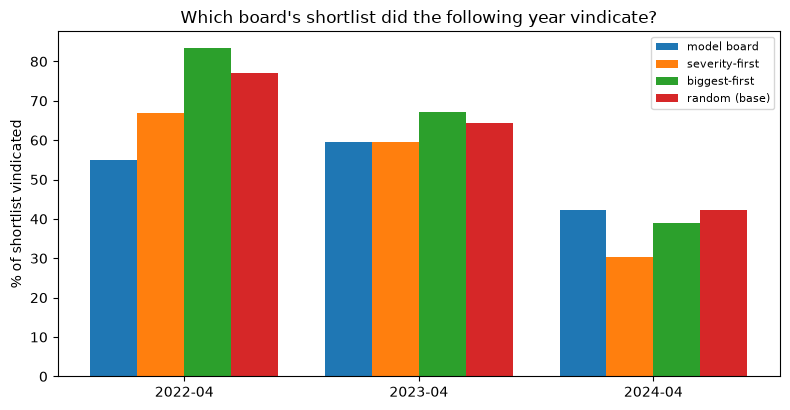

In [3]:
summary = (reg.groupby("origin")
              .agg(N_mean=("N", "mean"), base=("base_rate", "first"), n=("n_scorable", "first"),
                   model_mean=("model_board", "mean"), model_sd=("model_board", "std"),
                   severity=("severity_board", "mean"), size=("size_board", "mean")))
print(summary.round(1).to_string())
print()
for origin_s, r in summary.iterrows():
    verdict = []
    verdict.append("beats random" if r.model_mean > r.base else "DOES NOT beat random")
    verdict.append("beats severity-first" if r.model_mean > r.severity else "loses to severity-first")
    verdict.append("beats biggest-first" if r.model_mean > r.size else "loses to biggest-first")
    print(f"{origin_s}: model board {r.model_mean:.1f}% (sd {r.model_sd:.1f}) vs base {r.base:.1f}% "
          f"of {int(r.n):,} - " + ", ".join(verdict))
print()
print("Vindication = the service's >18-week queue grew >5% over the 12 months after the origin.")
print("All boards pick the same N per (origin, seed); the random board's expectation is the base rate.")

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(summary))
for i, colname in enumerate(["model_mean", "severity", "size", "base"]):
    ax.bar(x + i * 0.2, summary[colname], width=0.2,
           label=["model board", "severity-first", "biggest-first", "random (base)"][i])
ax.set_xticks(x + 0.3); ax.set_xticklabels(summary.index)
ax.set_ylabel("% of shortlist vindicated"); ax.legend(fontsize=8)
ax.set_title("Which board's shortlist did the following year vindicate?")
plt.tight_layout()

## What this settles

Whether the forecaster-led shortlist is the right thing to put in front of a board, measured the way
a board would measure it. It does not claim any capacity outcome - no allocation was executed - and
the demand-trained model is being scored here on a breach-growth vindication, which is exactly the
cross-variable gap `12` addresses; if `12`'s breach-trained call replaces the demand call, this
notebook is the harness that re-scores it.